# Building an XGBoost Model for Airline Passenger Satisfaction Prediction

## Overview
This project focuses on using machine learning techniques to predict airline passenger satisfaction. By leveraging the XGBoost algorithm, we aim to build a robust model that can accurately classify passengers as satisfied or dissatisfied based on various features such as flight distance, seat comfort, and service quality.

## Objective
Develop a machine learning model using XGBoost to predict passenger satisfaction. The project will cover the complete machine learning pipeline, including data preprocessing, feature engineering, model training, hyperparameter tuning, and evaluation.

## Learning Outcomes
1. Understand the importance of data preprocessing and feature engineering in machine learning.
2. Learn to implement and tune the XGBoost algorithm for classification tasks.
3. Gain experience in evaluating model performance using metrics such as accuracy, precision, recall, and F1 score.
4. Explore feature importance and interpret model results.
5. Compare the performance of XGBoost with other models like Decision Trees and Random Forests.

---

## Step 1: Define the Problem
### Task:
Understand the problem and its real-world implications. Predicting passenger satisfaction can help airlines improve customer experience, optimize services, and increase customer loyalty.

### Mini-task:
Write a brief paragraph on how predicting passenger satisfaction can benefit the airline industry.

---


At the end of a trip, it is essential for a cooperate transport or airline company to evaluate its passengers experience at the end of each trip. This will go a long way to expose their passenger's satisfaction or dissatisfaction also, so that the company will know where to make amends, improve in their services or initiate more measures to make their trip explorable, satisfactory as well as worthwhile.



## Step 2: Data Collection
### Task:
Collect a dataset suitable for predicting passenger satisfaction. The dataset used in this project is the `Invistico_Airline.csv`, which contains various features related to passenger experiences.

### Mini-task:
Load the dataset and inspect the first few rows to understand its structure.

#### Hint:
Use the `pandas` library to load the dataset and display the first 10 rows.

```python
import pandas as pd

# Load the dataset
airline_data = pd.read_csv('..\sample_data\Invistico_Airline.csv')

# Display the first 10 rows
### airline_data.head(10) ###
```

---


In [4]:
# Import Data Files from Google Drive

import requests
import pandas as pd
from io import StringIO
def read_gd(sharingurl):
    file_id = sharingurl.split('/')[-2]
    download_url='https://drive.google.com/uc?export=download&id=' + file_id
    url = requests.get(download_url).text
    csv_raw = StringIO(url)
    return csv_raw

url = "https://drive.google.com/file/d/1gG0NpYi2hUh8oaYJg7tIsb157D0Qgpzt/view?usp=sharing"
gdd = read_gd(url)

df = pd.read_csv(gdd)

df.head(10)

,satisfaction,Customer Type,Age,Type of Travel,Class,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,Gate location,...,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes
0,satisfied,Loyal Customer,65,Personal Travel,Eco,265,0,0,0,2,...,2,3,3,0,3,5,3,2,0,0.0
1,satisfied,Loyal Customer,47,Personal Travel,Business,2464,0,0,0,3,...,2,3,4,4,4,2,3,2,310,305.0
2,satisfied,Loyal Customer,15,Personal Travel,Eco,2138,0,0,0,3,...,2,2,3,3,4,4,4,2,0,0.0
3,satisfied,Loyal Customer,60,Personal Travel,Eco,623,0,0,0,3,...,3,1,1,0,1,4,1,3,0,0.0
4,satisfied,Loyal Customer,70,Personal Travel,Eco,354,0,0,0,3,...,4,2,2,0,2,4,2,5,0,0.0
5,satisfied,Loyal Customer,30,Personal Travel,Eco,1894,0,0,0,3,...,2,2,5,4,5,5,4,2,0,0.0
6,satisfied,Loyal Customer,66,Personal Travel,Eco,227,0,0,0,3,...,5,5,5,0,5,5,5,3,17,15.0
7,satisfied,Loyal Customer,10,Personal Travel,Eco,1812,0,0,0,3,...,2,2,3,3,4,5,4,2,0,0.0
8,satisfied,Loyal Customer,56,Personal Travel,Business,73,0,0,0,3,...,5,4,4,0,1,5,4,4,0,0.0
9,satisfied,Loyal Customer,22,Personal Travel,Eco,1556,0,0,0,3,...,2,2,2,4,5,3,4,2,30,26.0



## Step 3: Exploratory Data Analysis (EDA)
### Task:
Analyze the dataset to understand the distribution of features, identify missing values, and explore relationships between variables.

### Mini-task:
Visualize the distribution of the target variable (satisfaction) and inspect the data types of each column.

#### Hint:
Use `value_counts()` to check the distribution of the target variable and `dtypes` to inspect the data types.

```python
import matplotlib.pyplot as plt

# Visualize the distribution of the target variable
### YOUR CODE HERE ###

# Display data types
### YOUR CODE HERE ###
```

---


In [5]:
df['satisfaction'].unique()

array(['satisfied', 'dissatisfied'], dtype=object)

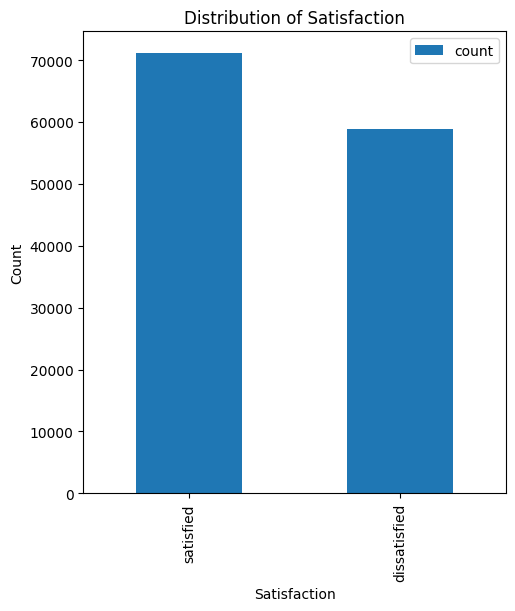

In [7]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
df['satisfaction'].value_counts().plot(kind='bar')
plt.xlabel('Satisfaction')
plt.ylabel('Count')
plt.title('Distribution of Satisfaction')
plt.legend()
plt.show()

In [9]:
# Analyze the data to understand the distribution of the features

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   satisfaction                       129880 non-null  object 
 1   Customer Type                      129880 non-null  object 
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  object 
 4   Class                              129880 non-null  object 
 5   Flight Distance                    129880 non-null  int64  
 6   Seat comfort                       129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Food and drink                     129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Inflight wifi service              129880 non-null  int64  
 11  Inflight entertainment             1298

In [10]:
# From the dataset, we can observe that there are some missing values in the "Arrival Delay in Minutes".
# Also the dataset contains integers, float as well as categorical values
# Display the datatypes of the features

print(df.dtypes)

satisfaction                          object
Customer Type                         object
Age                                    int64
Type of Travel                        object
Class                                 object
Flight Distance                        int64
Seat comfort                           int64
Departure/Arrival time convenient      int64
Food and drink                         int64
Gate location                          int64
Inflight wifi service                  int64
Inflight entertainment                 int64
Online support                         int64
Ease of Online booking                 int64
On-board service                       int64
Leg room service                       int64
Baggage handling                       int64
Checkin service                        int64
Cleanliness                            int64
Online boarding                        int64
Departure Delay in Minutes             int64
Arrival Delay in Minutes             float64
dtype: obj

In [11]:
# Let us access the descriptive Statistics of the dataset

df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,129880.0,39.427957,15.119360,7.0,27.0,40.0,51.0,85.0
Flight Distance,129880.0,1981.409055,1027.115606,50.0,1359.0,1925.0,2544.0,6951.0
Seat comfort,129880.0,2.838597,1.392983,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,129880.0,2.990645,1.527224,0.0,2.0,3.0,4.0,5.0
Food and drink,129880.0,2.851994,1.443729,0.0,2.0,3.0,4.0,5.0
Gate location,129880.0,2.990422,1.305970,0.0,2.0,3.0,4.0,5.0
Inflight wifi service,129880.0,3.249130,1.318818,0.0,2.0,3.0,4.0,5.0
Inflight entertainment,129880.0,3.383477,1.346059,0.0,2.0,4.0,4.0,5.0
Online support,129880.0,3.519703,1.306511,0.0,3.0,4.0,5.0,5.0
Ease of Online booking,129880.0,3.472105,1.305560,0.0,2.0,4.0,5.0,5.0


In [12]:
# Now let us check the total sum of missing values

missing_values = df.isna().sum()
missing_values

,0
satisfaction,0
Customer Type,0
Age,0
Type of Travel,0
Class,0
Flight Distance,0
Seat comfort,0
Departure/Arrival time convenient,0
Food and drink,0
Gate location,0


In [13]:
# Fill the 393 missing values with the mean of their column from the statistics

df['Arrival Delay in Minutes'].fillna(df['Arrival Delay in Minutes'].mean(), inplace=True)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   satisfaction                       129880 non-null  object 
 1   Customer Type                      129880 non-null  object 
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  object 
 4   Class                              129880 non-null  object 
 5   Flight Distance                    129880 non-null  int64  
 6   Seat comfort                       129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Food and drink                     129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Inflight wifi service              129880 non-null  int64  
 11  Inflight entertainment             1298

<ipython-input-13-dba38161090d>:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Arrival Delay in Minutes'].fillna(df['Arrival Delay in Minutes'].mean(), inplace=True)


In [14]:
# df.fillna({'Arrival Delay in Minutes': 15.091129}, inplace=True)
# df.info()


## Step 4: Data Preprocessing
### Task:
Preprocess the data to prepare it for modeling. This includes handling missing values, encoding categorical variables, and splitting the data into training and testing sets.

### Mini-task:
Convert categorical variables into numerical format using one-hot encoding and split the data into training and testing sets.

#### Hint:
Use `pd.get_dummies()` to encode categorical variables and `train_test_split()` to split the data.

```python
from sklearn.model_selection import train_test_split

# Convert categorical variables to numerical using one-hot encoding
### YOUR CODE HERE ###

# Define the target variable and features
### YOUR CODE HERE ###

# Split the data into training and testing sets
### YOUR CODE HERE ###
```

---


In [15]:
# Converting categorical variables to numerical using the get_dummies encoding

df = pd.get_dummies(df, columns=['satisfaction', 'Customer Type', 'Type of Travel', 'Class'], drop_first=True, dtype='int')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Age                                129880 non-null  int64  
 1   Flight Distance                    129880 non-null  int64  
 2   Seat comfort                       129880 non-null  int64  
 3   Departure/Arrival time convenient  129880 non-null  int64  
 4   Food and drink                     129880 non-null  int64  
 5   Gate location                      129880 non-null  int64  
 6   Inflight wifi service              129880 non-null  int64  
 7   Inflight entertainment             129880 non-null  int64  
 8   Online support                     129880 non-null  int64  
 9   Ease of Online booking             129880 non-null  int64  
 10  On-board service                   129880 non-null  int64  
 11  Leg room service                   1298

In [16]:
df.head(10)

,Age,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,Gate location,Inflight wifi service,Inflight entertainment,Online support,Ease of Online booking,...,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction_satisfied,Customer Type_disloyal Customer,Type of Travel_Personal Travel,Class_Eco,Class_Eco Plus
0,65,265,0,0,0,2,2,4,2,3,...,5,3,2,0,0.0,1,0,1,1,0
1,47,2464,0,0,0,3,0,2,2,3,...,2,3,2,310,305.0,1,0,1,0,0
2,15,2138,0,0,0,3,2,0,2,2,...,4,4,2,0,0.0,1,0,1,1,0
3,60,623,0,0,0,3,3,4,3,1,...,4,1,3,0,0.0,1,0,1,1,0
4,70,354,0,0,0,3,4,3,4,2,...,4,2,5,0,0.0,1,0,1,1,0
5,30,1894,0,0,0,3,2,0,2,2,...,5,4,2,0,0.0,1,0,1,1,0
6,66,227,0,0,0,3,2,5,5,5,...,5,5,3,17,15.0,1,0,1,1,0
7,10,1812,0,0,0,3,2,0,2,2,...,5,4,2,0,0.0,1,0,1,1,0
8,56,73,0,0,0,3,5,3,5,4,...,5,4,4,0,0.0,1,0,1,0,0
9,22,1556,0,0,0,3,2,0,2,2,...,3,4,2,30,26.0,1,0,1,1,0


In [17]:
# Set X and y variables
X = df.drop(columns = ['satisfaction_satisfied'])
y = df['satisfaction_satisfied']

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Step 5: Model Training Using XGBoost
### Task:
Train an XGBoost model on the preprocessed data. Perform hyperparameter tuning using GridSearchCV to find the optimal parameters.

### Mini-task:
Define the XGBoost classifier and perform hyperparameter tuning.

#### Hint:
Use `XGBClassifier()` and `GridSearchCV()` to tune hyperparameters like `max_depth`, `learning_rate`, and `n_estimators`.

```python
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

# Define the XGBoost classifier
### YOUR CODE HERE ###

# Define the parameters for hyperparameter tuning
### YOUR CODE HERE ###

# Perform GridSearchCV
### YOUR CODE HERE ###

# Display the best parameters
### YOUR CODE HERE ###
```

---

In [20]:
# Define the XGBoost classifier

import xgboost as xgb
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, classification_report


model = xgb.XGBClassifier(use_label_encoder=False, random_state=42)
model.fit(X_train_scaled, y_train)

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [09:32:39] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, random_state=42, ...)

In [21]:
# Display the accuracy of the model

from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test_scaled)
accuracy_metric = accuracy_score(y_test, y_pred)
print(accuracy_metric)
print(f'\n', classification_report(y_test, y_pred))

0.9580381890976286

               precision    recall  f1-score   support

           0       0.94      0.96      0.95     11675
           1       0.97      0.95      0.96     14301

    accuracy                           0.96     25976
   macro avg       0.96      0.96      0.96     25976
weighted avg       0.96      0.96      0.96     25976



In [22]:
# Display the confusion matrix

confusion_mat = confusion_matrix(y_test, y_pred)
print(confusion_mat)

[[11244   431]
 [  659 13642]]


<Figure size 800x400 with 0 Axes>

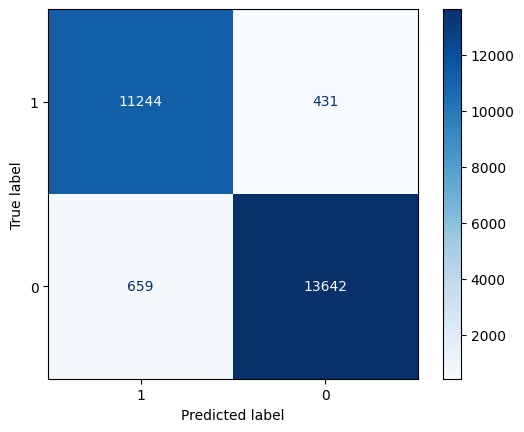

In [23]:
# Plot the Confusion Matrix of the trained model

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
cmd = ConfusionMatrixDisplay(confusion_matrix=confusion_mat, display_labels=df['satisfaction_satisfied'].unique())
cmd.plot(cmap=plt.cm.Blues)
plt.show()

In [24]:
# Define the GridSearch parameters

from sklearn.model_selection import GridSearchCV

params = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.1, 0.01, 0.001],
    'n_estimators': [100, 500, 1000]}


In [27]:
# Perform GridSearchCV

param_grid = GridSearchCV(estimator=model, param_grid=params, cv=5, n_jobs=-1, verbose=1)
param_grid.fit(X_train_scaled, y_train)


Fitting 5 folds for each of 27 candidates, totalling 135 fits


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [10:07:22] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, gamma=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=None,...
                                     max_cat_threshold=None,
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None,
                                     random_state=42, ...),
             n_jobs=-1,
             param_grid={'learning_rate': [0.1, 0.01, 0.001],
                         'max_depth': [3, 5, 7],
                         'n_estimators': [100, 500, 1000]},
             verbose=1)

In [28]:
# The GridSearchCV took about 10m:30s to process

#Display the best parameters

print(param_grid.best_params_)

{'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 500}


In [29]:
# Train the XGBoost Classifier with the GridSearch best parameters

model_2 = xgb.XGBClassifier(use_label_encoder=False, random_state=42, max_depth=7, learning_rate=0.1, n_estimators=500,
                            minimum_sample_leaf=60)
model_2.fit(X_train_scaled, y_train)

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [10:25:20] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "minimum_sample_leaf", "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=7, max_leaves=None,
              min_child_weight=None, minimum_sample_leaf=60, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=500,
              n_jobs=None, num_parallel_tree=None, ...)


## Step 6: Model Evaluation
### Task:
Evaluate the model's performance using metrics such as accuracy, precision, recall, and F1 score. Visualize the results using a confusion matrix and feature importance plot.

### Mini-task:
Evaluate the model on the test set and visualize the confusion matrix and feature importance.

#### Hint:
Use `accuracy_score()`, `precision_score()`, `recall_score()`, and `f1_score()` to evaluate the model. Use `confusion_matrix()` and `plot_importance()` for visualization.

```python
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Predict on the test set
### YOUR CODE HERE ###

# Calculate evaluation metrics
### YOUR CODE HERE ###

# Plot the confusion matrix
### YOUR CODE HERE ###

# Plot feature importance
### YOUR CODE HERE ###
```

---

In [33]:
# Predict on the test set
model_2_pred = model_2.predict(X_test_scaled)


In [32]:
# Calculate evaluation metrics
'''
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
accuracy = accuracy_score(y_test, grid_predictions)
precision = precision_score(y_test, grid_predictions)
recall = recall_score(y_test, grid_predictions)
f1 = f1_score(y_test, grid_predictions)

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")
'''

'\nfrom sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score\naccuracy = accuracy_score(y_test, grid_predictions)\nprecision = precision_score(y_test, grid_predictions)\nrecall = recall_score(y_test, grid_predictions)\nf1 = f1_score(y_test, grid_predictions)\n\nprint(f"Accuracy: {accuracy}")\nprint(f"Precision: {precision}")\nprint(f"Recall: {recall}")\nprint(f"F1 Score: {f1}")\n'

In [34]:
# Calculate evaluation metrics

model_2_accuracy = accuracy_score(y_test, model_2_pred)
print(model_2_accuracy)
print(f'\n', classification_report(y_test, model_2_pred))
model_2_report = classification_report(y_test, model_2_pred)
print(model_2_report)

0.9593470896211888

               precision    recall  f1-score   support

           0       0.95      0.96      0.96     11675
           1       0.97      0.96      0.96     14301

    accuracy                           0.96     25976
   macro avg       0.96      0.96      0.96     25976
weighted avg       0.96      0.96      0.96     25976

              precision    recall  f1-score   support

           0       0.95      0.96      0.96     11675
           1       0.97      0.96      0.96     14301

    accuracy                           0.96     25976
   macro avg       0.96      0.96      0.96     25976
weighted avg       0.96      0.96      0.96     25976



In [36]:
# Plot the confusion matrix

confusion_grid = confusion_matrix(y_test, model_2_pred)
print(confusion_grid)

[[11252   423]
 [  633 13668]]


<Figure size 800x400 with 0 Axes>

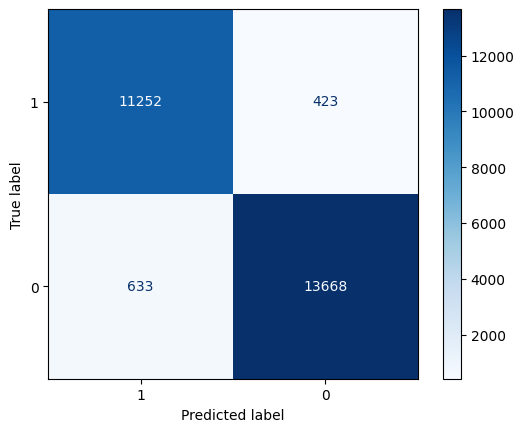

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay


plt.figure(figsize=(8, 4))
cmd = ConfusionMatrixDisplay(confusion_matrix=confusion_grid, display_labels=df['satisfaction_satisfied'].unique())
cmd.plot(cmap=plt.cm.Blues)
plt.show()

In [42]:
# Plot feature importance
importances = model_2.feature_importances_

f_importance = pd.DataFrame({'Feature': X.columns, 'Importance':  importances})
f_importance = f_importance.sort_values('Importance', ascending=False)
f_importance

,Feature,Importance
7,Inflight entertainment,0.409152
2,Seat comfort,0.148573
9,Ease of Online booking,0.066398
18,Customer Type_disloyal Customer,0.057837
19,Type of Travel_Personal Travel,0.035314
3,Departure/Arrival time convenient,0.028025
15,Online boarding,0.022629
5,Gate location,0.022103
20,Class_Eco,0.021663
10,On-board service,0.021649


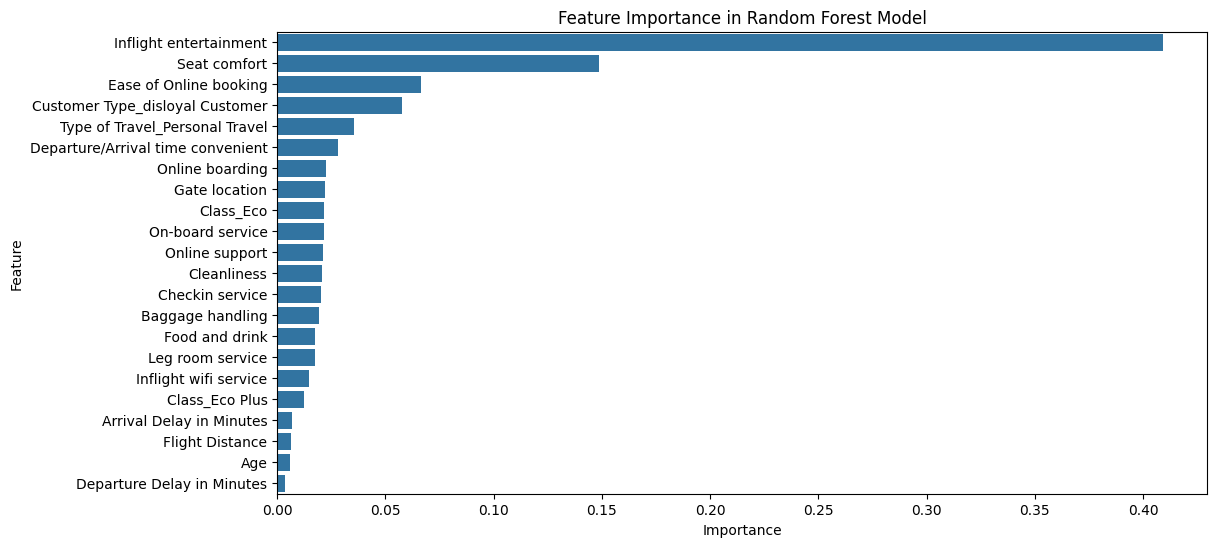

In [43]:
plt.figure(figsize=(12, 6))
sns.barplot(x='Importance', y='Feature', data=f_importance)
plt.title('Feature Importance in Random Forest Model')
plt.show()


## Step 7: Model Comparison (Optional)
### Task:
Compare the performance of the XGBoost model with other models like Decision Trees and Random Forests.

### Mini-task:
Train a Decision Tree and Random Forest model, and compare their performance with the XGBoost model.

#### Hint:
Use `DecisionTreeClassifier()` and `RandomForestClassifier()` to train the models and compare their accuracy.

```python
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Train a Decision Tree model
### YOUR CODE HERE ###

# Train a Random Forest model
### YOUR CODE HERE ###

# Compare model performance
### YOUR CODE HERE ###
```

---

In [50]:
# Train a Decision Tree model

from sklearn.tree import DecisionTreeClassifier

dtc_model = DecisionTreeClassifier()
dtc_model.fit(X_train_scaled, y_train)

DecisionTreeClassifier()

In [51]:
# Set the parameters for the DecisionTreeClassifier GridSearchCV

import numpy as np

dtc_params = {'max_depth' : np.arange(1, 8)}

dtc_grid = GridSearchCV(dtc_model, param_grid=dtc_params, cv=5)
dtc_grid.fit(X_train_scaled, y_train)



GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'max_depth': array([1, 2, 3, 4, 5, 6, 7])})

In [52]:
print(dtc_grid.best_params_)

{'max_depth': np.int64(7)}


In [53]:
# Evaluate the DecisionTreeClassifier Performance

dtc_pred = dtc_grid.predict(X_test_scaled)
dtc_accuracy = accuracy_score(y_test, dtc_pred)
print(dtc_accuracy)


0.8954419464120726


In [56]:
dtc_grid_report = classification_report(y_test, dtc_pred)
print(dtc_grid_report)

              precision    recall  f1-score   support

           0       0.85      0.93      0.89     11675
           1       0.93      0.87      0.90     14301

    accuracy                           0.90     25976
   macro avg       0.89      0.90      0.90     25976
weighted avg       0.90      0.90      0.90     25976



In [57]:
print(dtc_grid.best_score_)

0.8916788550509718


In [60]:
# Train the model using RandomForestClassifier

from sklearn.ensemble import RandomForestClassifier

rfc_model = RandomForestClassifier()
rfc_model.fit(X_train_scaled, y_train)

RandomForestClassifier()

In [74]:

rfc_params = {'max_depth': [3, 5, 10],
              'n_estimators': [10, 50, 100]}

In [76]:
# Compute the Hyperparameter Tuning
from sklearn.model_selection import RandomizedSearchCV

rfc_grid = RandomizedSearchCV(estimator=rfc_model, param_distributions=rfc_params, cv=5)


In [77]:
rfc_grid.fit(X_train_scaled, y_train)

/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 9 is smaller than n_iter=10. Running 9 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(),
                   param_distributions={'max_depth': [3, 5, 10],
                                        'n_estimators': [10, 50, 100]})

In [79]:
print(rfc_grid.best_params_)

{'n_estimators': 50, 'max_depth': 10}


In [80]:
rfc_pred = rfc_grid.predict(X_test_scaled)

In [82]:
rfc_score = accuracy_score(y_test, rfc_pred)

print(rfc_score)
rfc_report = classification_report(y_test, rfc_pred)
print(rfc_report)

0.9263550970126271
              precision    recall  f1-score   support

           0       0.92      0.91      0.92     11675
           1       0.93      0.94      0.93     14301

    accuracy                           0.93     25976
   macro avg       0.93      0.92      0.93     25976
weighted avg       0.93      0.93      0.93     25976



In [83]:
# Compare Model Performance

from sklearn.ensemble import VotingClassifier

class_models = VotingClassifier(estimators=[('xgboost', model_2), ('dtc', dtc_grid), ('rfc', rfc_grid)])
best_model = class_models.fit(X_train_scaled, y_train)
print(best_model)

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [11:21:28] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "minimum_sample_leaf", "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 9 is smaller than n_iter=10. Running 9 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


VotingClassifier(estimators=[('xgboost',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_metric=None,
                                            feature_types=None, gamma=None,
                                            grow_policy=None,
                                            importance_type=None,
                                            interaction_constraints=None,
                                            learnin...
                                            monotone_constraints=None,
 

In [ ]:
# From the above evalution using the VotingClassifier, we can see that the XGBoost model is the best model so far in predicting the satisfaction of the passengers having come up
# with a hyperparameter tuning accuracy score of 96%

# We see from the Confusion Matrix that the hypertuning helped to indicate the best features that contributed to the passenger satisfaction with the airline. Also it reduced the number of false positives and false negatives as can be
# seen from the confusion Matrix Display


In [87]:
model_2.score(X_test_scaled, y_test)

0.9593470896211888

## Considerations
**What are some key takeaways you learned from this project?**
- Reflect on the importance of hyperparameter tuning and feature engineering.
- Consider how the model's insights can be applied to improve airline services.

**How would you share your findings with a team?**
- Prepare a presentation with visualizations and key metrics.
- Discuss the impact of different features on passenger satisfaction.

**What would you share with and recommend to stakeholders?**
- Highlight the key features that contribute most to passenger satisfaction.
- Recommend strategies to improve services based on the model's insights.

Some of the key take away I learnt from the project is that:

1. Hyperparameter tuning is an essential method the fine tune a model's performance and accuracy as it gives room to fine tune any model accuracy.
2. The classification report helped us to visualize the performance of our model at a glance thereby giving room for fine tuning.
3, XGBoost gives a higher performance compared to Decision Tree and Random Forest.


. Consider how the model's insights can be applied to improve airline services.

As was seen from the feature Immportance chart, Inflight entertainment recorded the best feature to contribute to passenger's satifaction during the flight trip with a rate of	0.409152, Seat comfort contributing 0.148573 and Ease of Online booking contributing	0.066398.
The Airline Management should improve on other features and add a boost to these identified features for a steady and improved services.

Stategies to improve services based on the model's insights include
Cleanliness, Ceckin service, Baggage handling, Flight Distance amongst others
